# Bagian D - Semantic Segmentation CamVid
Fine-tuning **DeepLabV3 + MobileNetV3-Large** (pretrained COCO) ke **11 kelas CamVid**.

Notebook ini bisa dijalankan di **Kaggle** atau **lokal (GPU CUDA)**, lokasi dataset dicari otomatis.

**Kaggle**
1. *Add Input* -> dataset `carlolepelaars/camvid`
2. *Settings* -> Accelerator **GPU T4**, **Internet: On** (untuk download bobot pretrained torchvision)
3. *Run All*, lalu download `camvid_deeplabv3_mbv3.pth` dari panel *Output* -> taruh di `src/semantic_segmentation/model/`

**Lokal**
1. Ekstrak dataset Kaggle ke `data/CamVid/` (isi: `train/`, `train_labels/`, `val/`, `val_labels/`, `test/`, `test_labels/`, `class_dict.csv`)
2. Buka notebook ini dari folder `src/semantic_segmentation/` (Jupyter / VS Code), *Run All*
3. Model langsung tersimpan di `src/semantic_segmentation/model/camvid_deeplabv3_mbv3.pth`

Alur: data -> pemetaan 32 kelas ke 11 kelas -> fine-tuning -> evaluasi data test -> simpan model.

In [1]:
import os, glob, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import (deeplabv3_mobilenet_v3_large,
                                             DeepLabV3_MobileNet_V3_Large_Weights)

# seed supaya hasil training bisa diulang
random.seed(0); np.random.seed(0); torch.manual_seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
if device.type == 'cpu':
    print('PERINGATAN: GPU tidak terdeteksi, training di CPU akan sangat lambat')

device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Konfigurasi

In [2]:
# lokasi dataset & tempat menyimpan model
found = glob.glob('/kaggle/input/**/class_dict.csv', recursive=True)
if found:
    # di Kaggle: folder input bisa beda-beda namanya, jadi dicari dari letak class_dict.csv
    DATA_ROOT = os.path.dirname(found[0])
    OUT_PATH  = '/kaggle/working/camvid_deeplabv3_mbv3.pth'
else:
    # lokal: notebook ada di src/semantic_segmentation/, dataset di data/CamVid/ (root repo)
    DATA_ROOT = os.path.join('..', '..', 'data', 'CamVid')
    OUT_PATH  = os.path.join('model', 'camvid_deeplabv3_mbv3.pth')
    os.makedirs('model', exist_ok=True)
assert os.path.isfile(os.path.join(DATA_ROOT, 'class_dict.csv')), f'dataset tidak ditemukan di {DATA_ROOT}'
print('DATA_ROOT:', os.path.abspath(DATA_ROOT), sorted(os.listdir(DATA_ROOT)))
print('OUT_PATH :', os.path.abspath(OUT_PATH))

IMG_SIZE   = (360, 480)   # (H, W) = setengah resolusi asli 720x960, supaya cepat di GPU T4
BATCH_SIZE = 8             # turunkan ke 4 kalau GPU kehabisan memori (CUDA out of memory)
EPOCHS     = 50
LR         = 5e-4
NUM_WORKERS = 0            # data sudah di memori, 0 juga aman di Windows (>0 sering hang di Jupyter Windows)

# mean/std ImageNet, sama dengan normalisasi saat backbone di-pretrain
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

DATA_ROOT: c:\Users\Muzaraar\Documents\Kuliah\Kelas_Kuliah\Semester_7\Citra Digital\Tugas3-IF4073-CitraDigital-13523104\data\CamVid ['class_dict.csv', 'test', 'test_labels', 'train', 'train_labels', 'val', 'val_labels']
OUT_PATH : c:\Users\Muzaraar\Documents\Kuliah\Kelas_Kuliah\Semester_7\Citra Digital\Tugas3-IF4073-CitraDigital-13523104\src\semantic_segmentation\model\camvid_deeplabv3_mbv3.pth


## 2. Pemetaan 32 kelas CamVid -> 11 kelas
Pengelompokan mengikuti contoh MathWorks. Kelas `Void` (piksel tidak berlabel) diberi nilai 255
dan **diabaikan** saat menghitung loss maupun metrik.

In [3]:
# 11 kelas tugas -> kelas-kelas asli CamVid yang digabung ke dalamnya
CLASS_GROUPS = {
    'Sky':        ['Sky'],
    'Building':   ['Building', 'Wall', 'Tunnel', 'Archway', 'Bridge'],
    'Pole':       ['Column_Pole', 'TrafficCone'],
    'Road':       ['Road', 'LaneMkgsDriv', 'LaneMkgsNonDriv'],
    'Pavement':   ['Sidewalk', 'ParkingBlock', 'RoadShoulder'],
    'Tree':       ['Tree', 'VegetationMisc'],
    'SignSymbol': ['SignSymbol', 'Misc_Text', 'TrafficLight'],
    'Fence':      ['Fence'],
    'Car':        ['Car', 'SUVPickupTruck', 'Truck_Bus', 'Train', 'OtherMoving'],
    'Pedestrian': ['Pedestrian', 'Child', 'CartLuggagePram', 'Animal'],
    'Bicyclist':  ['Bicyclist', 'MotorcycleScooter'],
}
CLASS_NAMES = list(CLASS_GROUPS.keys())
NUM_CLASSES = len(CLASS_NAMES)   # 11
IGNORE = 255                     # Void / warna tak dikenal -> tidak ikut loss & metrik

# warna tiap kelas untuk visualisasi (sama dengan camvidColorMap di contoh MathWorks)
PALETTE = [[128, 128, 128], [128, 0, 0], [192, 192, 192], [128, 64, 128],
           [60, 40, 222], [128, 128, 0], [192, 128, 128], [64, 64, 128],
           [64, 0, 128], [64, 64, 0], [0, 128, 192]]

# class_dict.csv: nama kelas asli + warna RGB-nya di citra label
class_dict = pd.read_csv(os.path.join(DATA_ROOT, 'class_dict.csv'))
class_dict.columns = ['name', 'r', 'g', 'b']

# kode warna (r*65536 + g*256 + b) -> indeks kelas 0..10, Void -> 255
CODE_TO_IDX = {}
for _, row in class_dict.iterrows():
    code = int(row['r']) * 65536 + int(row['g']) * 256 + int(row['b'])
    CODE_TO_IDX[code] = IGNORE
    for idx, name in enumerate(CLASS_NAMES):
        if row['name'] in CLASS_GROUPS[name]:
            CODE_TO_IDX[code] = idx


def rgb_to_label(rgb):
    """label RGB CamVid (H x W x 3) -> label indeks (H x W), nilai 0..10 atau 255"""
    rgb = rgb.astype(np.int32)
    code = rgb[..., 0] * 65536 + rgb[..., 1] * 256 + rgb[..., 2]
    label = np.full(code.shape, IGNORE, dtype=np.uint8)   # warna tak dikenal -> diabaikan
    for c, idx in CODE_TO_IDX.items():
        label[code == c] = idx
    return label


def label_to_color(label):
    """label indeks -> citra RGB untuk ditampilkan (255 / Void -> hitam)"""
    lut = np.zeros((256, 3), dtype=np.uint8)
    lut[:NUM_CLASSES] = PALETTE
    return lut[label]


def add_legend(ax):
    patches = [mpatches.Patch(color=np.array(c) / 255, label=n) for n, c in zip(CLASS_NAMES, PALETTE)]
    ax.legend(handles=patches, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)

In [4]:
# cek pemetaan: semua kelas di class_dict.csv (kecuali Void) masuk ke salah satu dari 11 kelas,
# dan tidak ada salah ketik nama kelas di CLASS_GROUPS
csv_names = set(class_dict['name'])
group_names = [n for names in CLASS_GROUPS.values() for n in names]
not_mapped = sorted(csv_names - set(group_names) - {'Void'})
typo = sorted(set(group_names) - csv_names)
print(f'{len(csv_names)} kelas di class_dict.csv, {len(group_names)} dipetakan ke {NUM_CLASSES} kelas, Void diabaikan')
assert not not_mapped, f'kelas belum dipetakan: {not_mapped}'
assert not typo, f'nama kelas tidak ada di class_dict.csv: {typo}'

32 kelas di class_dict.csv, 31 dipetakan ke 11 kelas, Void diabaikan


## 3. Dataset
Pembagian data memakai split bawaan dataset Kaggle (split standar CamVid):
**train 369 / val 100 / test 232**. Frame dari sekuens video yang sama tidak tersebar di split
yang berbeda, jadi data test benar-benar belum pernah dilihat model.

In [5]:
def list_pairs(split):
    """pasangan path (citra, label) untuk split 'train' / 'val' / 'test'"""
    img_paths = sorted(glob.glob(os.path.join(DATA_ROOT, split, '*.png')))
    # nama file label = nama citra + akhiran _L
    lbl_paths = [os.path.join(DATA_ROOT, split + '_labels', os.path.basename(p)[:-4] + '_L.png')
                 for p in img_paths]
    return img_paths, lbl_paths


class CamVid(Dataset):
    def __init__(self, split, train=False):
        self.train = train
        H, W = IMG_SIZE
        img_paths, lbl_paths = list_pairs(split)

        # semua data dimuat ke memori sekali di awal (cuma ratusan citra kecil) supaya training cepat
        self.images, self.labels = [], []
        for ip, lp in zip(img_paths, lbl_paths):
            img = Image.open(ip).convert('RGB').resize((W, H), Image.BILINEAR)
            # label di-resize NEAREST supaya warna kelas tidak tercampur jadi warna baru
            lbl = Image.open(lp).convert('RGB').resize((W, H), Image.NEAREST)
            self.images.append(np.asarray(img))
            self.labels.append(rgb_to_label(np.asarray(lbl)))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img, lbl = self.images[i], self.labels[i]
        if self.train and random.random() < 0.5:      # augmentasi: flip horizontal
            img, lbl = img[:, ::-1], lbl[:, ::-1]
        x = (img.astype(np.float32) / 255.0 - np.array(MEAN)) / np.array(STD)
        x = torch.from_numpy(x.transpose(2, 0, 1).copy()).float()   # H x W x 3 -> 3 x H x W
        y = torch.from_numpy(lbl.astype(np.int64))
        return x, y


train_ds = CamVid('train', train=True)
val_ds   = CamVid('val')
test_ds  = CamVid('test')
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

train 369 | val 100 | test 232


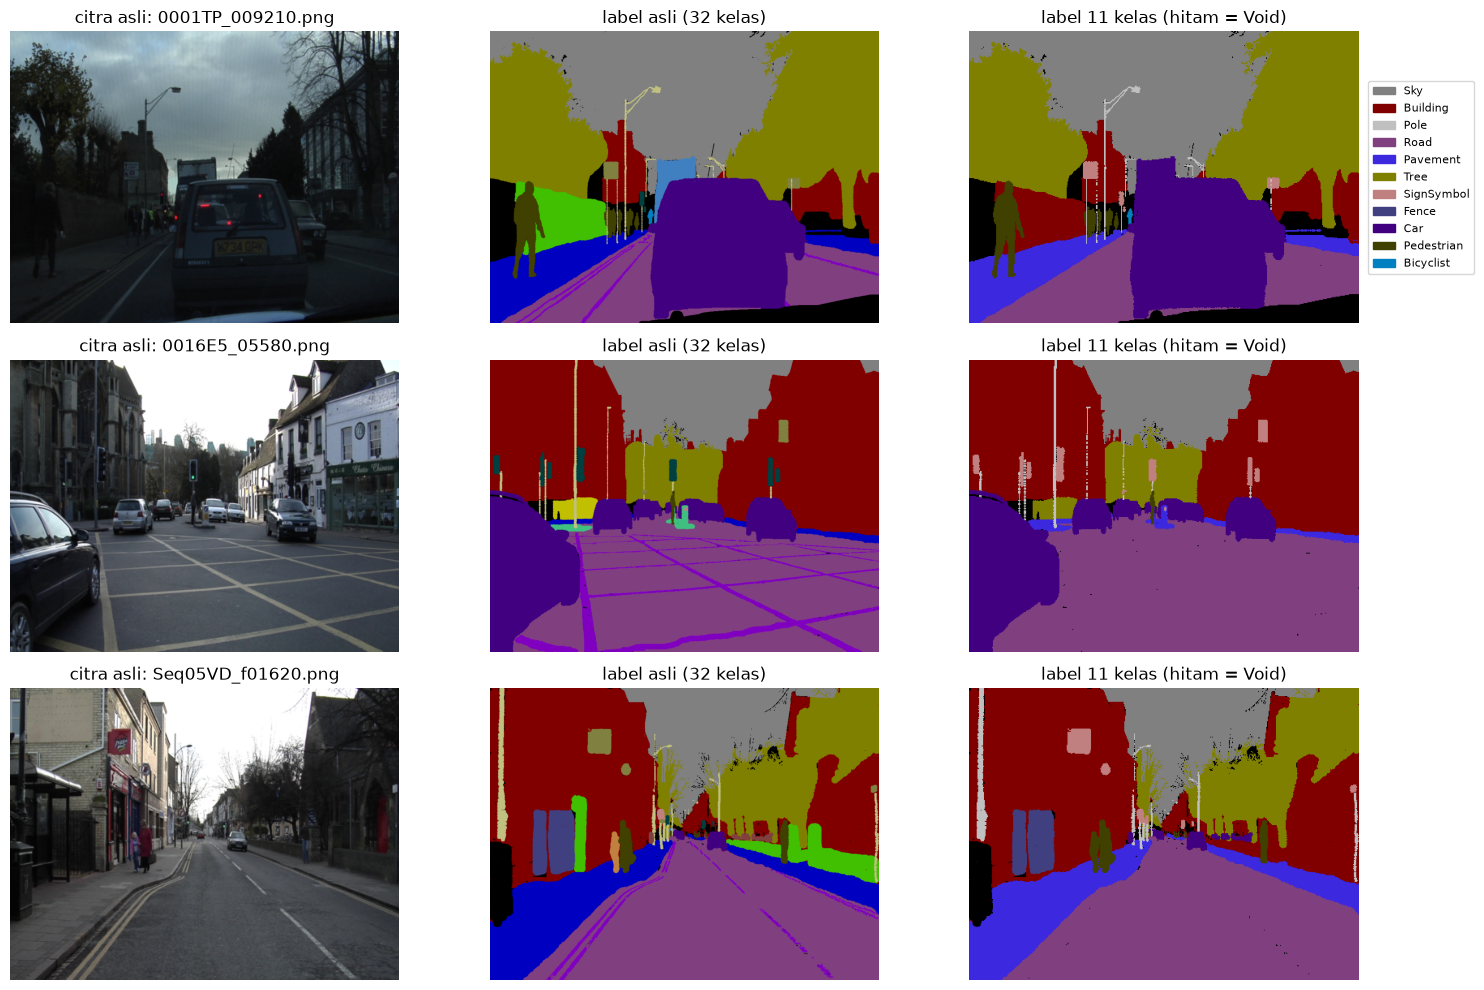

In [6]:
# contoh data: citra asli | label asli (32 kelas) | label setelah dipetakan ke 11 kelas
img_paths, lbl_paths = list_pairs('train')
fig, ax = plt.subplots(3, 3, figsize=(16, 10))
for r, k in enumerate([0, 150, 300]):
    ax[r, 0].imshow(train_ds.images[k]);    ax[r, 0].set_title('citra asli: ' + os.path.basename(img_paths[k]))
    ax[r, 1].imshow(Image.open(lbl_paths[k])); ax[r, 1].set_title('label asli (32 kelas)')
    ax[r, 2].imshow(label_to_color(train_ds.labels[k])); ax[r, 2].set_title('label 11 kelas (hitam = Void)')
for a in ax.flat:
    a.axis('off')
add_legend(ax[0, 2])
plt.tight_layout(); plt.show()

## 4. Bobot kelas (median frequency balancing)
Piksel Road/Sky/Building jauh lebih banyak daripada Pole/SignSymbol/Bicyclist. Tanpa pembobotan,
model cenderung mengabaikan kelas kecil. Bobot kelas c = median(freq) / freq(c), dengan
freq(c) = jumlah piksel kelas c / jumlah piksel citra yang memuat kelas c (cara yang sama dengan contoh MathWorks).

In [7]:
pixel_count = np.zeros(NUM_CLASSES)   # jumlah piksel tiap kelas
image_pixels = np.zeros(NUM_CLASSES)  # jumlah piksel citra yang memuat kelas tsb
for lbl in train_ds.labels:
    for c in range(NUM_CLASSES):
        n = np.sum(lbl == c)
        if n > 0:
            pixel_count[c] += n
            image_pixels[c] += lbl.size

freq = pixel_count / image_pixels
class_weights = np.median(freq) / freq
print(pd.DataFrame({'kelas': CLASS_NAMES, 'frekuensi': freq.round(4), 'bobot': class_weights.round(3)}))

         kelas  frekuensi  bobot
0          Sky     0.1517  0.285
1     Building     0.2418  0.179
2         Pole     0.0104  4.146
3         Road     0.3050  0.142
4     Pavement     0.0765  0.566
5         Tree     0.1197  0.362
6   SignSymbol     0.0120  3.596
7        Fence     0.0291  1.486
8          Car     0.0433  1.000
9   Pedestrian     0.0075  5.765
10   Bicyclist     0.0095  4.561


## 5. Model pretrained + transfer learning
DeepLabV3 dengan backbone MobileNetV3-Large, bobot pretrained COCO (21 kelas VOC).
Layer klasifikasi terakhir diganti menjadi 11 kelas, lalu **seluruh jaringan di-fine-tune** dengan data CamVid.

In [8]:
model = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)

# transfer learning: layer terakhir (conv 1x1, 21 kelas VOC) diganti jadi 11 kelas CamVid
model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
model.aux_classifier = None      # cabang auxiliary tidak dipakai
model = model.to(device)
print(model.classifier)

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to C:\Users\Muzaraar/.cache\torch\hub\checkpoints\deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:24<00:00, 1.78MB/s]


DeepLabHead(
  (0): ASPP(
    (convs): ModuleList(
      (0): Sequential(
        (0): Conv2d(960, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (1): ASPPConv(
        (0): Conv2d(960, 256, kernel_size=(3, 3), stride=(1, 1), padding=(12, 12), dilation=(12, 12), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (2): ASPPConv(
        (0): Conv2d(960, 256, kernel_size=(3, 3), stride=(1, 1), padding=(24, 24), dilation=(24, 24), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (3): ASPPConv(
        (0): Conv2d(960, 256, kernel_size=(3, 3), stride=(1, 1), padding=(36, 36), dilation=(36, 36), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, mome

## 6. Training
Metrik: **IoU** tiap kelas = TP / (TP + FP + FN), **mIoU** = rata-rata IoU 11 kelas,
**pixel accuracy** = piksel benar / semua piksel berlabel. Model dengan mIoU validasi terbaik yang disimpan.

In [9]:
def evaluate(model, loader):
    """confusion matrix seluruh data -> IoU tiap kelas, mIoU, pixel accuracy"""
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)['out'].argmax(1)
            valid = y != IGNORE
            # baris = label sebenarnya, kolom = prediksi
            idx = y[valid] * NUM_CLASSES + pred[valid]
            conf += torch.bincount(idx, minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)
    conf = conf.cpu().numpy().astype(np.float64)
    tp = np.diag(conf)
    iou = tp / np.maximum(conf.sum(0) + conf.sum(1) - tp, 1)
    acc = tp.sum() / conf.sum()
    return iou, iou.mean(), acc


def save_checkpoint(path):
    # info kelas & preprocessing ikut disimpan supaya camvid_predict.py tidak perlu menyalinnya
    torch.save({'arch': 'deeplabv3_mobilenet_v3_large',
                'state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
                'class_names': CLASS_NAMES,
                'palette': PALETTE,
                'input_size': list(IMG_SIZE),
                'mean': MEAN,
                'std': STD}, path)


weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weights, ignore_index=IGNORE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)   # lr turun pelan ke 0

history = {'loss': [], 'val_miou': [], 'val_acc': []}
best_miou = -1
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    total_loss = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = criterion(model(x)['out'], y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()

    _, val_miou, val_acc = evaluate(model, val_dl)
    history['loss'].append(total_loss / len(train_dl))
    history['val_miou'].append(val_miou)
    history['val_acc'].append(val_acc)

    note = ''
    if val_miou > best_miou:
        best_miou = val_miou
        save_checkpoint(OUT_PATH)
        note = '  <- disimpan'
    print(f'epoch {epoch:2d} | loss {history["loss"][-1]:.3f} | val mIoU {val_miou:.3f} '
          f'| val acc {val_acc:.3f} | {time.time() - t0:.0f}s{note}')

epoch  1 | loss 1.056 | val mIoU 0.463 | val acc 0.748 | 11s  <- disimpan
epoch  2 | loss 0.610 | val mIoU 0.512 | val acc 0.781 | 10s  <- disimpan
epoch  3 | loss 0.495 | val mIoU 0.549 | val acc 0.819 | 11s  <- disimpan
epoch  4 | loss 0.446 | val mIoU 0.554 | val acc 0.832 | 11s  <- disimpan
epoch  5 | loss 0.391 | val mIoU 0.580 | val acc 0.860 | 11s  <- disimpan
epoch  6 | loss 0.372 | val mIoU 0.594 | val acc 0.866 | 11s  <- disimpan
epoch  7 | loss 0.350 | val mIoU 0.618 | val acc 0.880 | 10s  <- disimpan
epoch  8 | loss 0.324 | val mIoU 0.623 | val acc 0.881 | 10s  <- disimpan
epoch  9 | loss 0.313 | val mIoU 0.618 | val acc 0.879 | 10s
epoch 10 | loss 0.300 | val mIoU 0.615 | val acc 0.870 | 10s
epoch 11 | loss 0.285 | val mIoU 0.636 | val acc 0.892 | 11s  <- disimpan
epoch 12 | loss 0.275 | val mIoU 0.632 | val acc 0.887 | 11s
epoch 13 | loss 0.266 | val mIoU 0.640 | val acc 0.894 | 11s  <- disimpan
epoch 14 | loss 0.258 | val mIoU 0.638 | val acc 0.889 | 11s
epoch 15 | loss 

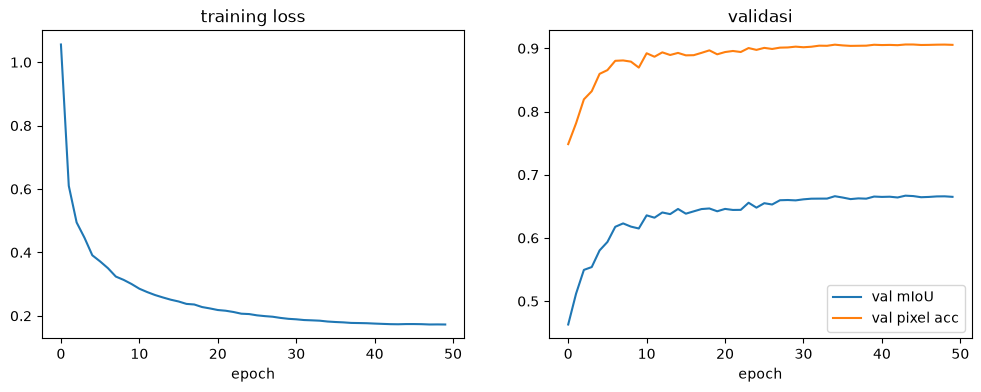

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['loss']);     ax[0].set_title('training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(history['val_miou'], label='val mIoU')
ax[1].plot(history['val_acc'], label='val pixel acc')
ax[1].set_title('validasi'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

## 7. Evaluasi pada data test

In [11]:
# pakai model terbaik (mIoU validasi tertinggi), bukan model epoch terakhir
ckpt = torch.load(OUT_PATH, map_location=device)
model.load_state_dict(ckpt['state_dict'])

test_iou, test_miou, test_acc = evaluate(model, test_dl)
print(pd.DataFrame({'kelas': CLASS_NAMES, 'IoU': test_iou.round(3)}).to_string(index=False))
print(f'\nmIoU test     : {test_miou:.3f}')
print(f'pixel acc test: {test_acc:.3f}')

     kelas   IoU
       Sky 0.897
  Building 0.807
      Pole 0.184
      Road 0.931
  Pavement 0.744
      Tree 0.765
SignSymbol 0.376
     Fence 0.547
       Car 0.772
Pedestrian 0.421
 Bicyclist 0.556

mIoU test     : 0.636
pixel acc test: 0.893


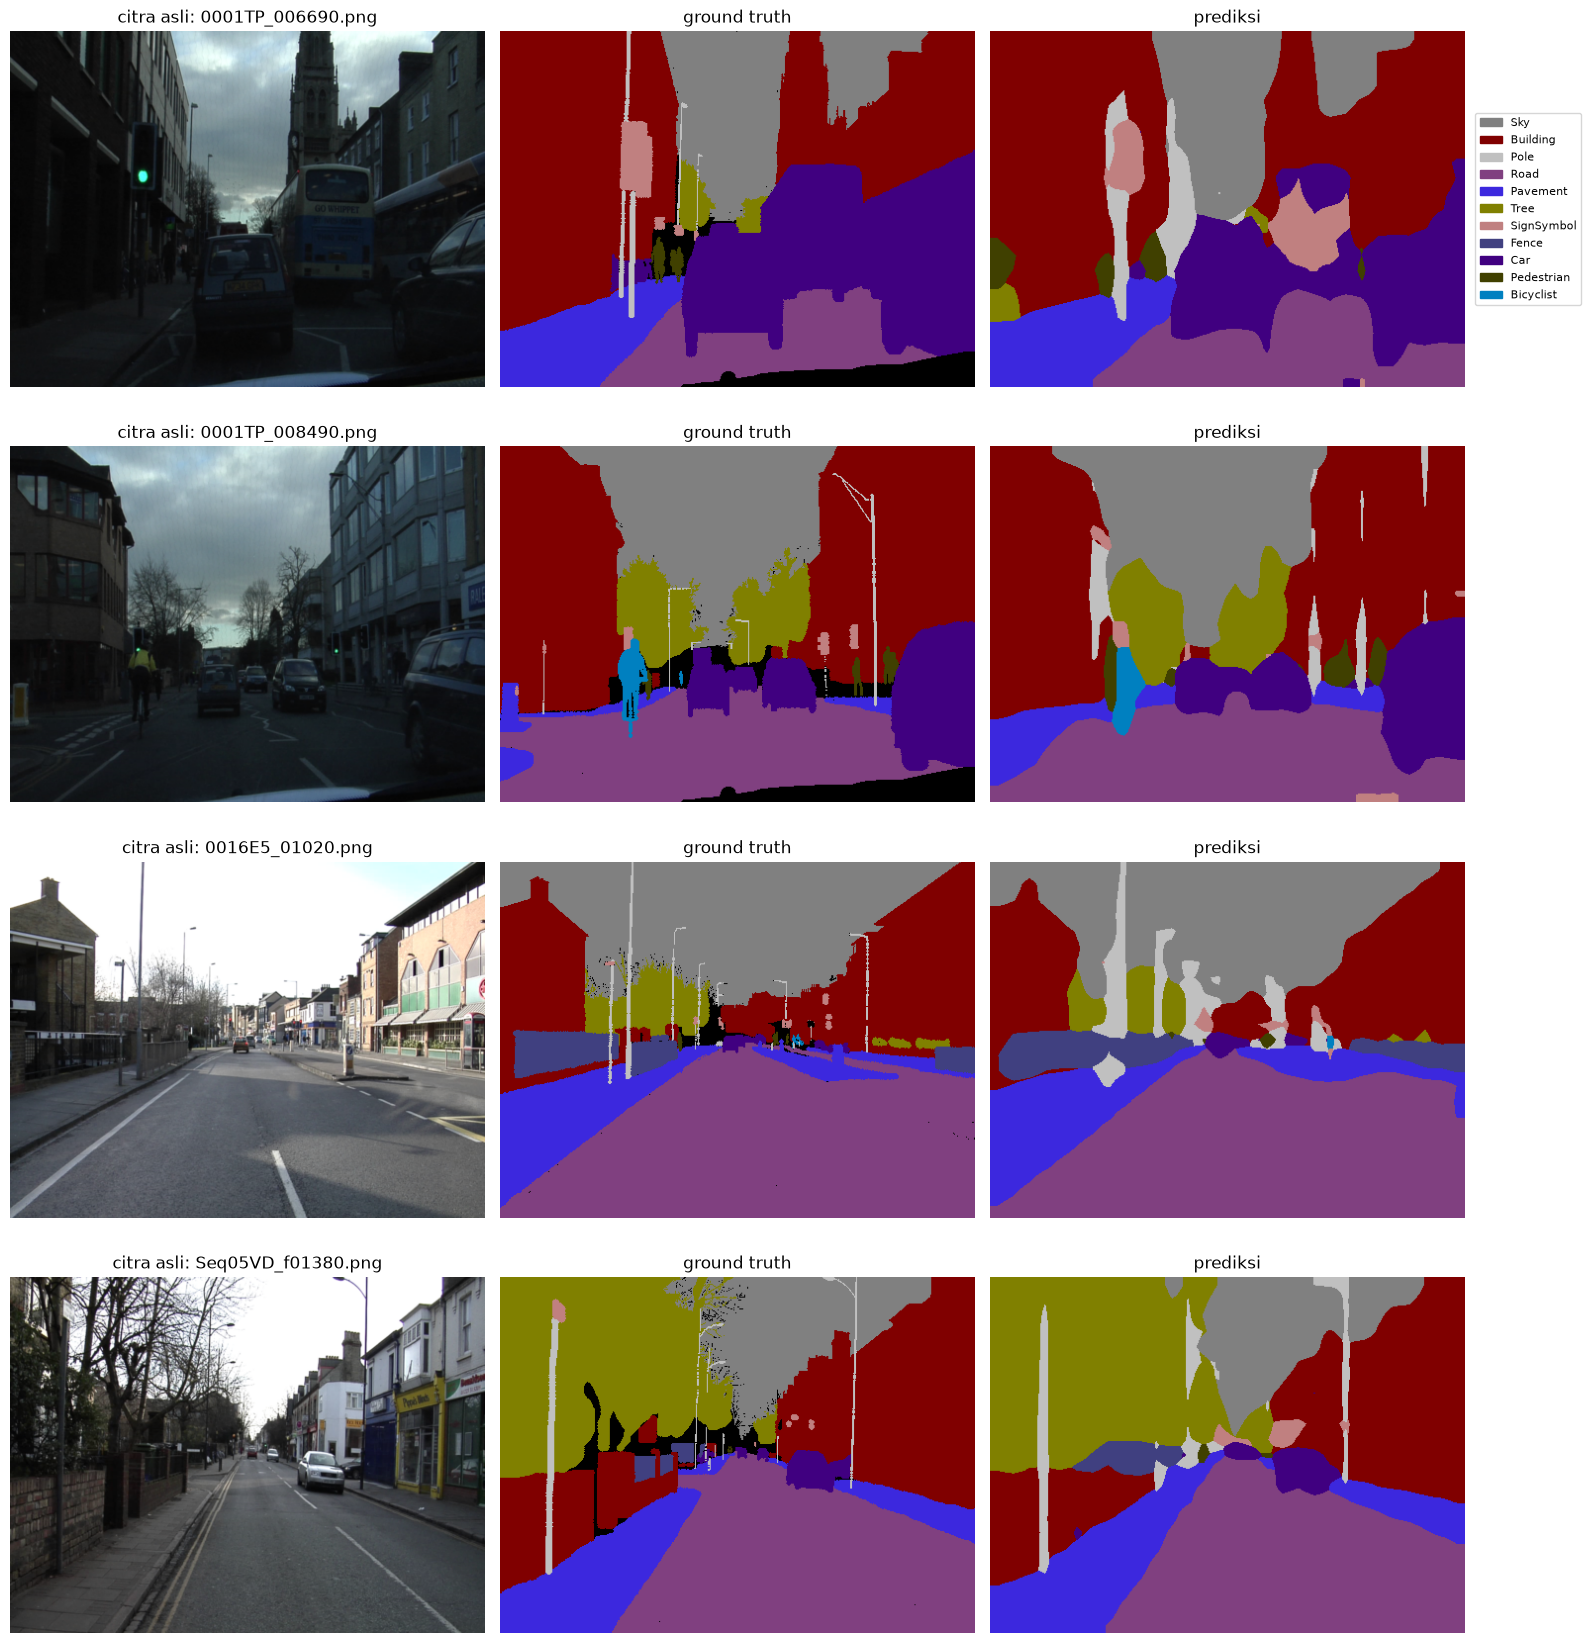

In [12]:
# contoh hasil: citra asli | ground truth | prediksi
model.eval()
picks = [0, 60, 120, 200]
fig, ax = plt.subplots(len(picks), 3, figsize=(16, 4.2 * len(picks)))
test_imgs, _ = list_pairs('test')
for r, k in enumerate(picks):
    x, _ = test_ds[k]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(device))['out'].argmax(1)[0].cpu().numpy().astype(np.uint8)
    ax[r, 0].imshow(test_ds.images[k]);              ax[r, 0].set_title('citra asli: ' + os.path.basename(test_imgs[k]))
    ax[r, 1].imshow(label_to_color(test_ds.labels[k])); ax[r, 1].set_title('ground truth')
    ax[r, 2].imshow(label_to_color(pred));            ax[r, 2].set_title('prediksi')
for a in ax.flat:
    a.axis('off')
add_legend(ax[0, 2])
plt.tight_layout(); plt.show()

## 8. Simpan model
- **Kaggle**: file `/kaggle/working/camvid_deeplabv3_mbv3.pth` muncul di panel **Output**,
  download lalu taruh di `src/semantic_segmentation/model/camvid_deeplabv3_mbv3.pth`.
- **Lokal**: model sudah langsung tersimpan di `model/camvid_deeplabv3_mbv3.pth`.